# Rennes Bicycle and Pedestrian Activity Analysis

## Project Overview

This project explores how average recorded bicycle and pedestrian activity varies by year, day of the week, hour, and counting location using open data from Rennes Métropole.

The analysis focuses on two named counting locations between 2020 and 2025:

- Eco-Display Place de Bretagne
- Rennes Rue d'Isly V1

The workflow covers data-quality assessment, missing-value handling, UTC-to-local-time conversion, coverage validation, exploratory analysis, and portfolio-ready visualizations.

All results are descriptive. Differences in data coverage are considered, missing observations are not treated as zero, and no causal conclusions are made.

## 1. Data Loading


In [1]:
import pandas as pd

df = pd.read_csv('data/raw/rennes_bike_pedestrian_counts_2026-11-05.csv')
display(df.head(5))

,date,isoDate,counts,status,ID,name,sens,counter,geo
0,2020-05-03T00:00:00+02:00,2020-05-02T22:00:00+0200,3.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"
1,2020-05-03T01:00:00+02:00,2020-05-02T23:00:00+0200,1.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"
2,2020-05-03T02:00:00+02:00,2020-05-03T00:00:00+0200,1.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"
3,2020-05-03T06:00:00+02:00,2020-05-03T04:00:00+0200,0.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"
4,2020-05-03T10:00:00+02:00,2020-05-03T08:00:00+0200,3.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"


## 2. Initial Data Quality Assessment

In [2]:
# inspaccion incial
print(df.shape)
print(df.columns)
df.info()

(165994, 9)
Index(['date', 'isoDate', 'counts', 'status', 'ID', 'name', 'sens', 'counter',
       'geo'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 165994 entries, 0 to 165993
Data columns (total 9 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   date     165994 non-null  str    
 1   isoDate  165994 non-null  str    
 2   counts   162227 non-null  float64
 3   status   162227 non-null  float64
 4   ID       165994 non-null  int64  
 5   name     134578 non-null  str    
 6   sens     134578 non-null  float64
 7   counter  134578 non-null  str    
 8   geo      134578 non-null  str    
dtypes: float64(3), int64(1), str(5)
memory usage: 11.4 MB


In [3]:
#control de calidad 
missing_values=df.isna().sum()
print(missing_values)
missing_percent=(missing_values/len(df))*100
print(missing_percent)
print(df.duplicated().sum())

date           0
isoDate        0
counts      3767
status      3767
ID             0
name       31416
sens       31416
counter    31416
geo        31416
dtype: int64
date        0.000000
isoDate     0.000000
counts      2.269359
status      2.269359
ID          0.000000
name       18.925985
sens       18.925985
counter    18.925985
geo        18.925985
dtype: float64
0


In [4]:
missing_count=df['counts'].isna()
display(df[missing_count].head(5))
missing_name=df['name'].isna()
display(df[missing_name].head(5))
print(df['status'].isna().equals(missing_count))

,date,isoDate,counts,status,ID,name,sens,counter,geo
1966,2014-11-06T01:00:00+01:00,2014-11-06T00:00:00+0100,NaN,NaN,100017942,NaN,NaN,NaN,NaN
1967,2014-11-06T05:00:00+01:00,2014-11-06T04:00:00+0100,NaN,NaN,100017942,NaN,NaN,NaN,NaN
1968,2014-11-06T09:00:00+01:00,2014-11-06T08:00:00+0100,NaN,NaN,100017942,NaN,NaN,NaN,NaN
2658,2015-03-29T04:00:00+02:00,2015-03-29T02:00:00+0100,NaN,NaN,100017942,NaN,NaN,NaN,NaN
6554,2024-05-30T17:00:00+02:00,2024-05-30T15:00:00+0200,NaN,NaN,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"


,date,isoDate,counts,status,ID,name,sens,counter,geo
1966,2014-11-06T01:00:00+01:00,2014-11-06T00:00:00+0100,NaN,NaN,100017942,NaN,NaN,NaN,NaN
1967,2014-11-06T05:00:00+01:00,2014-11-06T04:00:00+0100,NaN,NaN,100017942,NaN,NaN,NaN,NaN
1968,2014-11-06T09:00:00+01:00,2014-11-06T08:00:00+0100,NaN,NaN,100017942,NaN,NaN,NaN,NaN
1969,2014-11-06T17:00:00+01:00,2014-11-06T16:00:00+0100,50.0,0.0,100017942,NaN,NaN,NaN,NaN
1970,2014-11-07T00:00:00+01:00,2014-11-06T23:00:00+0100,3.0,0.0,100017942,NaN,NaN,NaN,NaN


True


In [5]:
missing_sens= df['sens'].isna()
missing_counter= df['counter'].isna()
missing_geo= df['geo'].isna()

same_metadata_pattern= (
    missing_name.equals(missing_sens)
    and missing_name.equals(missing_counter)
    and missing_name.equals(missing_geo)
)

print(same_metadata_pattern)

missing_name_ids = df.loc[missing_name, 'ID']

print(missing_name_ids.nunique())
print(missing_name_ids.value_counts())

True
1
ID
100017942    31416
Name: count, dtype: int64


In [6]:
print(df.loc[missing_name, 'counts'].isna().sum())
print(df.loc[~missing_name,'counts'].isna().sum())
print(df.loc[missing_name,'counts'].notna().sum())

17
3750
31399


## 3. Data Cleaning

In [7]:
df_clean=df.copy()
df_clean = df_clean.dropna(subset=['counts'])
display(df_clean.head())


,date,isoDate,counts,status,ID,name,sens,counter,geo
0,2020-05-03T00:00:00+02:00,2020-05-02T22:00:00+0200,3.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"
1,2020-05-03T01:00:00+02:00,2020-05-02T23:00:00+0200,1.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"
2,2020-05-03T02:00:00+02:00,2020-05-03T00:00:00+0200,1.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"
3,2020-05-03T06:00:00+02:00,2020-05-03T04:00:00+0200,0.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"
4,2020-05-03T10:00:00+02:00,2020-05-03T08:00:00+0200,3.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"


In [8]:
print('the shape is:' +  str(df_clean.shape))
print('the missing counts are: ' + str(df_clean['counts'].isna().sum()))
print('the missing status are: ' + str(df_clean['status'].isna().sum()))

print(df_clean.isna().sum())

the shape is:(162227, 9)
the missing counts are: 0
the missing status are: 0
date           0
isoDate        0
counts         0
status         0
ID             0
name       31399
sens       31399
counter    31399
geo        31399
dtype: int64


## 4. Local Time Preparation

In [9]:
df_clean['datetime_utc']=pd.to_datetime(df_clean['date'], utc=True, errors='coerce')
print(df_clean['datetime_utc'].isna().sum())
df_clean['datetime_local']=df_clean['datetime_utc'].dt.tz_convert("Europe/Paris")
display(df_clean[['datetime_utc', 'datetime_local']].head())

0


,datetime_utc,datetime_local
0,2020-05-02 22:00:00+00:00,2020-05-03 00:00:00+02:00
1,2020-05-02 23:00:00+00:00,2020-05-03 01:00:00+02:00
2,2020-05-03 00:00:00+00:00,2020-05-03 02:00:00+02:00
3,2020-05-03 04:00:00+00:00,2020-05-03 06:00:00+02:00
4,2020-05-03 08:00:00+00:00,2020-05-03 10:00:00+02:00


In [10]:
df_clean['year']=df_clean['datetime_local'].dt.year
df_clean['month']=df_clean['datetime_local'].dt.month
df_clean['day_name']= df_clean['datetime_local'].dt.day_name()
df_clean['hour']= df_clean['datetime_local'].dt.hour
display(df_clean[['year','month','day_name','hour','datetime_local']].head())

,year,month,day_name,hour,datetime_local
0,2020,5,Sunday,0,2020-05-03 00:00:00+02:00
1,2020,5,Sunday,1,2020-05-03 01:00:00+02:00
2,2020,5,Sunday,2,2020-05-03 02:00:00+02:00
3,2020,5,Sunday,6,2020-05-03 06:00:00+02:00
4,2020,5,Sunday,10,2020-05-03 10:00:00+02:00


In [11]:
print('the minimum local tim is: ' + str(df_clean['datetime_local'].min()))
print('the maximum local time is: ' + str(df_clean['datetime_local'].max()))
print('the numer of ditinct IDs is: ' + str(df_clean['ID'].nunique()))
print('the quantity of obvserbations per year are: ')
display(df_clean['year'].value_counts().sort_index())

the minimum local tim is: 2014-11-06 14:00:00+01:00
the maximum local time is: 2026-07-06 06:00:00+02:00
the numer of ditinct IDs is: 3
the quantity of obvserbations per year are: 


year
2014     1330
2015     8759
2016     8783
2017     8759
2018     8495
2019    15808
2020    17566
2021    17054
2022    15774
2023    17518
2024    16670
2025    17084
2026     8627
Name: count, dtype: int64

In [12]:
ID_Year=df_clean.groupby(['year','ID']).size()
display(ID_Year)

year  ID       
2014  100017942    1330
2015  100017942    8759
2016  100017942    8783
2017  100017942    8759
2018  100017942    3768
      100045818    4727
2019  100045818    8759
      100050719    7049
2020  100045818    8783
      100050719    8783
2021  100045818    8759
      100050719    8295
2022  100045818    8759
      100050719    7015
2023  100045818    8759
      100050719    8759
2024  100045818    8754
      100050719    7916
2025  100045818    8759
      100050719    8325
2026  100045818    4469
      100050719    4158
dtype: int64

In [13]:
df_IDloc=df_clean[['ID','name','sens','counter','geo']].copy()
df_IDloc=df_IDloc.drop_duplicates().sort_values('ID')
display(df_IDloc)

,ID,name,sens,counter,geo
1969,100017942,NaN,NaN,NaN,NaN
19031,100045818,Eco-Display Place de Bretagne,5.0,YTH18065596,"48.11003, -1.68414"
0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767"


## 5. Analysis Scope and Coverage

In [14]:
analysis_mask=(df_clean['year'].between(2020, 2025) & df_clean['ID'].isin([100045818, 100050719]))
df_analysis=df_clean[analysis_mask].copy()
display(df_analysis.head())
df_analysis.shape
print(sorted(df_analysis['year'].unique().tolist()))
print(sorted(df_analysis["ID"].unique().tolist()))

,date,isoDate,counts,status,ID,name,sens,counter,geo,datetime_utc,datetime_local,year,month,day_name,hour
0,2020-05-03T00:00:00+02:00,2020-05-02T22:00:00+0200,3.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767",2020-05-02 22:00:00+00:00,2020-05-03 00:00:00+02:00,2020,5,Sunday,0
1,2020-05-03T01:00:00+02:00,2020-05-02T23:00:00+0200,1.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767",2020-05-02 23:00:00+00:00,2020-05-03 01:00:00+02:00,2020,5,Sunday,1
2,2020-05-03T02:00:00+02:00,2020-05-03T00:00:00+0200,1.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767",2020-05-03 00:00:00+00:00,2020-05-03 02:00:00+02:00,2020,5,Sunday,2
3,2020-05-03T06:00:00+02:00,2020-05-03T04:00:00+0200,0.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767",2020-05-03 04:00:00+00:00,2020-05-03 06:00:00+02:00,2020,5,Sunday,6
4,2020-05-03T10:00:00+02:00,2020-05-03T08:00:00+0200,3.0,0.0,100050719,Rennes Rue d'Isly V1,5.0,Y2H19037896,"48.10572, -1.67767",2020-05-03 08:00:00+00:00,2020-05-03 10:00:00+02:00,2020,5,Sunday,10


[2020, 2021, 2022, 2023, 2024, 2025]
[100045818, 100050719]


In [15]:
coverage_table=(
    df_analysis
    .groupby(['year','ID'])
    .size()
    .unstack()
    )
display(coverage_table)

ID,100045818,100050719
year,,
2020,8783,8783
2021,8759,8295
2022,8759,7015
2023,8759,8759
2024,8754,7916
2025,8759,8325


## 6. Temporal Analysis and Visualizations

In [16]:
average_counts_table = (df_analysis
.groupby(['year','name'])
['counts']
.mean()
.unstack())
display(average_counts_table.round(2))

name,Eco-Display Place de Bretagne,Rennes Rue d'Isly V1
year,,
2020,76.82,32.03
2021,90.85,37.71
2022,98.55,40.97
2023,89.74,41.08
2024,98.70,41.78
2025,109.55,42.27


In [17]:
weekday_average_table = (df_analysis
.groupby(['day_name','name'])
['counts']
.mean()
.unstack()
)
display(weekday_average_table.round(2))

name,Eco-Display Place de Bretagne,Rennes Rue d'Isly V1
day_name,,
Friday,103.56,43.34
Monday,91.64,37.37
Saturday,85.48,37.14
Sunday,53.62,25.57
Thursday,109.50,43.88
Tuesday,108.60,44.17
Wednesday,105.72,42.87


In [18]:
weekday_order = ['Monday', 'Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday_average_table = weekday_average_table.reindex(weekday_order)
display(weekday_average_table.round(2))

name,Eco-Display Place de Bretagne,Rennes Rue d'Isly V1
day_name,,
Monday,91.64,37.37
Tuesday,108.60,44.17
Wednesday,105.72,42.87
Thursday,109.50,43.88
Friday,103.56,43.34
Saturday,85.48,37.14
Sunday,53.62,25.57


In [19]:
hourly_average_table = (df_analysis
    .groupby(['hour','name'])           
    ['counts']
    .mean()
    .unstack()          
    )
display(hourly_average_table.round(2))

name,Eco-Display Place de Bretagne,Rennes Rue d'Isly V1
hour,,
0,49.05,31.96
1,36.33,21.67
2,22.94,13.56
3,13.01,8.93
4,7.63,5.38
5,7.23,4.06
6,6.91,3.21
7,9.04,3.85
8,36.85,8.61


In [20]:
hourly_coverage_table = (df_analysis
.groupby(['hour','name'])
['counts']
.size()
.unstack()
)
display(hourly_coverage_table)

name,Eco-Display Place de Bretagne,Rennes Rue d'Isly V1
hour,,
0,2191,2050
1,2191,2044
2,2190,2036
3,2190,2036
4,2184,2030
5,2190,2036
6,2190,2040
7,2191,2047
8,2191,2047


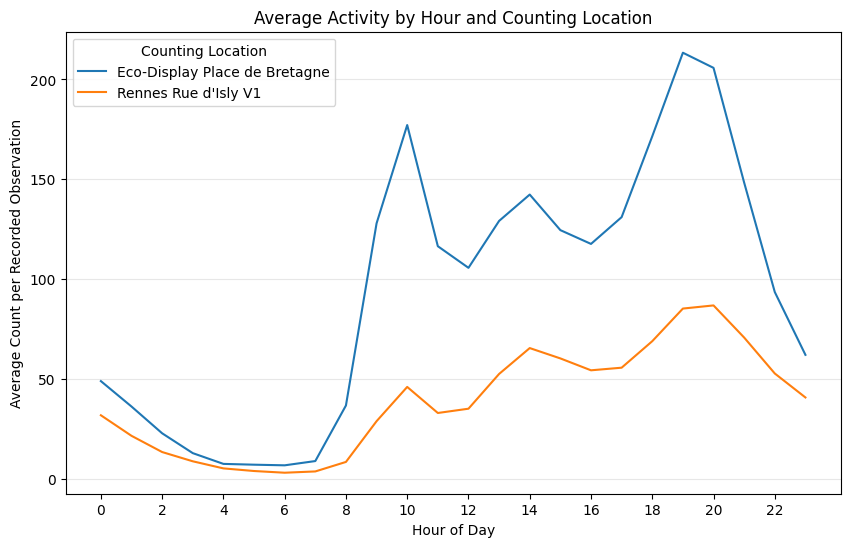

In [21]:
ax= hourly_average_table.plot(figsize=(10,6))
ax.set_title('Average Activity by Hour and Counting Location');
ax.set_xlabel('Hour of Day');
ax.set_ylabel('Average Count per Recorded Observation');
ax.set_xticks(range(0,24,2));
ax.legend(title='Counting Location');
ax.grid(axis='y',alpha=0.3)


The chart compares average recorded activity by hour at two counting locations in Rennes. Both locations show broadly similar temporal patterns, with local peaks around 10:00, 14:00, and 19:00–20:00, although average counts are consistently higher at Place de Bretagne.

In [22]:
from pathlib import Path

output_path = Path("figures/hourly_average_by_location.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

ax.figure.savefig(output_path, dpi=300, bbox_inches="tight")

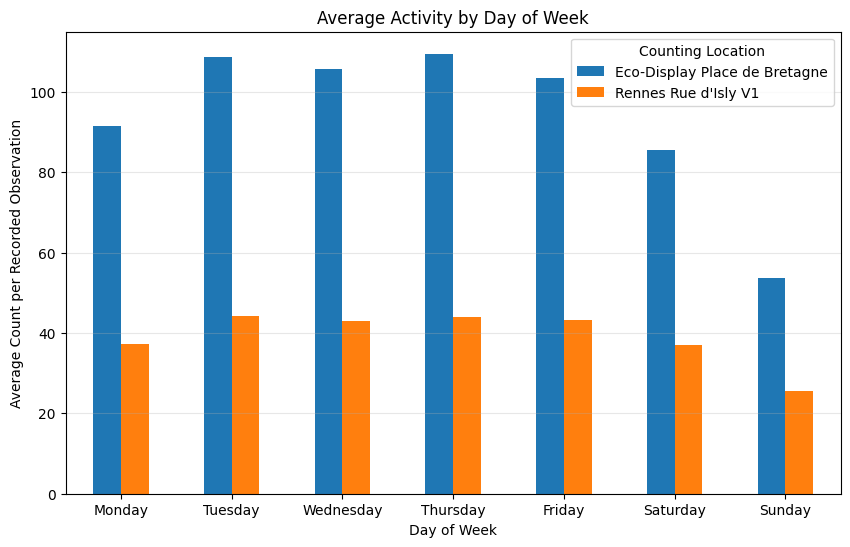

In [23]:
bx=weekday_average_table.plot(figsize=(10,6),kind='bar',rot=0)
bx.set_title('Average Activity by Day of Week');
bx.set_xlabel('Day of Week');
bx.set_ylabel('Average Count per Recorded Observation');
bx.legend(title='Counting Location');
bx.grid(axis='y',alpha=0.3)

The chart compares average recorded activity by day of the week at two counting locations. Place de Bretagne records higher averages throughout the week and peaks on Thursday, while Rue d’Isly peaks on Tuesday. Both locations show lower average activity during the weekend, with Sunday recording the lowest values.

In [24]:
output_path = Path("figures/weekday_average_by_location.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

bx.figure.savefig(output_path, dpi=300, bbox_inches="tight")

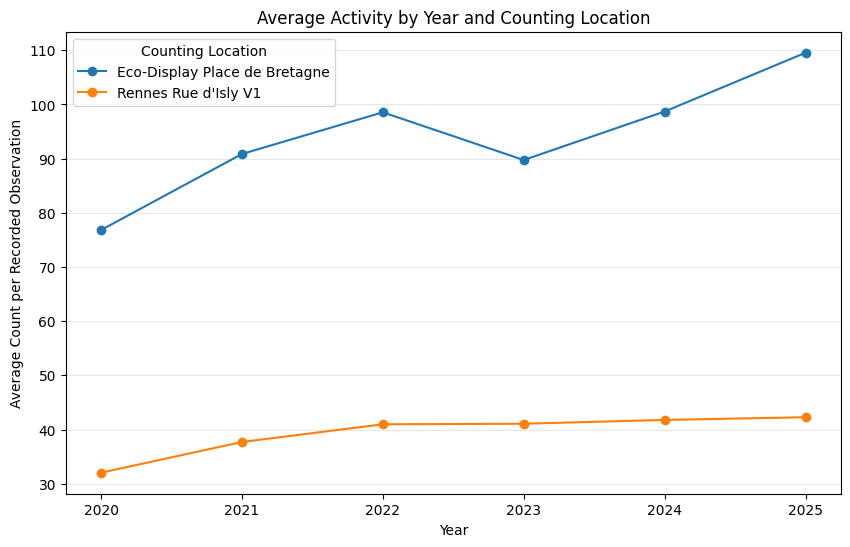

In [25]:
cx= average_counts_table.plot(kind='line',figsize=(10,6),marker='o')
cx.set_title('Average Activity by Year and Counting Location')
cx.set_xlabel('Year')
cx.set_ylabel('Average Count per Recorded Observation')
cx.legend(title='Counting Location')
cx.grid(axis='y',alpha=0.3)

The chart shows that Place de Bretagne has a higher average recorded count throughout the 2020–2025 period. Both counting locations reach their highest average in 2025. Rue d’Isly shows a steadier upward trend, whereas Place de Bretagne declines in 2023 before rising again. These results are descriptive averages, and differences in yearly coverage should be considered.

In [26]:
output_path = Path("figures/yearly_average_by_location.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

cx.figure.savefig(output_path, dpi=300, bbox_inches="tight")